# 图 5：香港夏季温度与降雨量关联

香港天文台站，1991–2025 年，每年 6–8 月。横轴为夏季总雨量（mm），纵轴为夏季平均气温（°C），每个点对应同一年的两项指标。

输入：`data/metrics/annual_summer_metrics.csv`。先检查年份唯一、每年 92 天完整，再按年份配对。拟合线使用带截距的普通最小二乘（OLS），以雨量为自变量、温度为因变量，仅画在实际观测雨量范围内。

这是未经去趋势的描述性图；图中关联不代表因果。去趋势相关、异常年份影响和不确定性分析属于第四步。


In [1]:
from pathlib import Path

import matplotlib as mpl
import polars as pl
from IPython.display import Image
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure

from hk_summer_weather.temperature_rainfall import prepare_temperature_rainfall

current_directory = Path.cwd()
project_root = (
    current_directory
    if (current_directory / "pyproject.toml").exists()
    else current_directory.parent
)
annual = pl.read_csv(project_root / "data/metrics/annual_summer_metrics.csv")
points = prepare_temperature_rainfall(annual)

In [2]:
style = {
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": "#243746",
    "axes.labelcolor": "#243746",
    "xtick.color": "#51616D",
    "ytick.color": "#51616D",
    "svg.fonttype": "path",
}

with mpl.rc_context(style):
    figure = Figure(figsize=(8.6, 6.4), facecolor="white")
    canvas = FigureCanvasAgg(figure)
    axes = figure.add_axes((0.115, 0.235, 0.84, 0.59))
    scatter = axes.scatter(
        points.rainfall_mm,
        points.mean_temperature_c,
        s=54,
        color="#246C8A",
        edgecolors="white",
        linewidths=0.7,
        alpha=0.9,
        label="One summer",
        zorder=3,
    )
    line = axes.plot(
        points.fitted_rainfall_mm,
        points.fitted_temperature_c,
        color="#C05A37",
        linewidth=2,
        label="Linear fit (OLS)",
        zorder=2,
    )
    axes.set_xlabel("Summer total rainfall (mm)", labelpad=12)
    axes.set_ylabel("Summer mean temperature (°C)", labelpad=12)
    axes.grid(axis="y", color="#E5EAED", linewidth=0.7, zorder=0)
    axes.set_axisbelow(True)
    axes.spines[["top", "right"]].set_visible(False)
    for spine in ("left", "bottom"):
        axes.spines[spine].set_color("#B8C3CA")
    axes.tick_params(length=3, color="#B8C3CA")
    axes.margins(x=0.08, y=0.12)
    axes.legend(loc="upper right", frameon=False, fontsize=9)
    figure.text(
        0.115,
        0.93,
        "Figure 5. Summer temperature and rainfall",
        fontsize=16,
        weight="bold",
    )
    figure.text(
        0.115,
        0.88,
        (
            "Hong Kong Observatory · June-August, "
            f"{int(points.years.min())}-{int(points.years.max())} · "
            f"n = {points.years.size} complete summers"
        ),
        fontsize=10,
        color="#51616D",
    )
    figure.text(
        0.115,
        0.10,
        (
            "One point per year; unadjusted linear fit. "
            "Association does not imply causation."
        ),
        fontsize=8.5,
        color="#51616D",
    )
    figure.text(
        0.115,
        0.06,
        (
            "Source: Hong Kong Observatory daily observations; "
            "project annual summer metrics."
        ),
        fontsize=8.5,
        color="#51616D",
    )

## 保存与预览

保存 300 dpi PNG（用于报告）和 SVG 矢量图（便于缩放、排版）。SVG 将字体转为路径，避免换电脑后出现字体替换。两个文件都保存在 `figures/`。


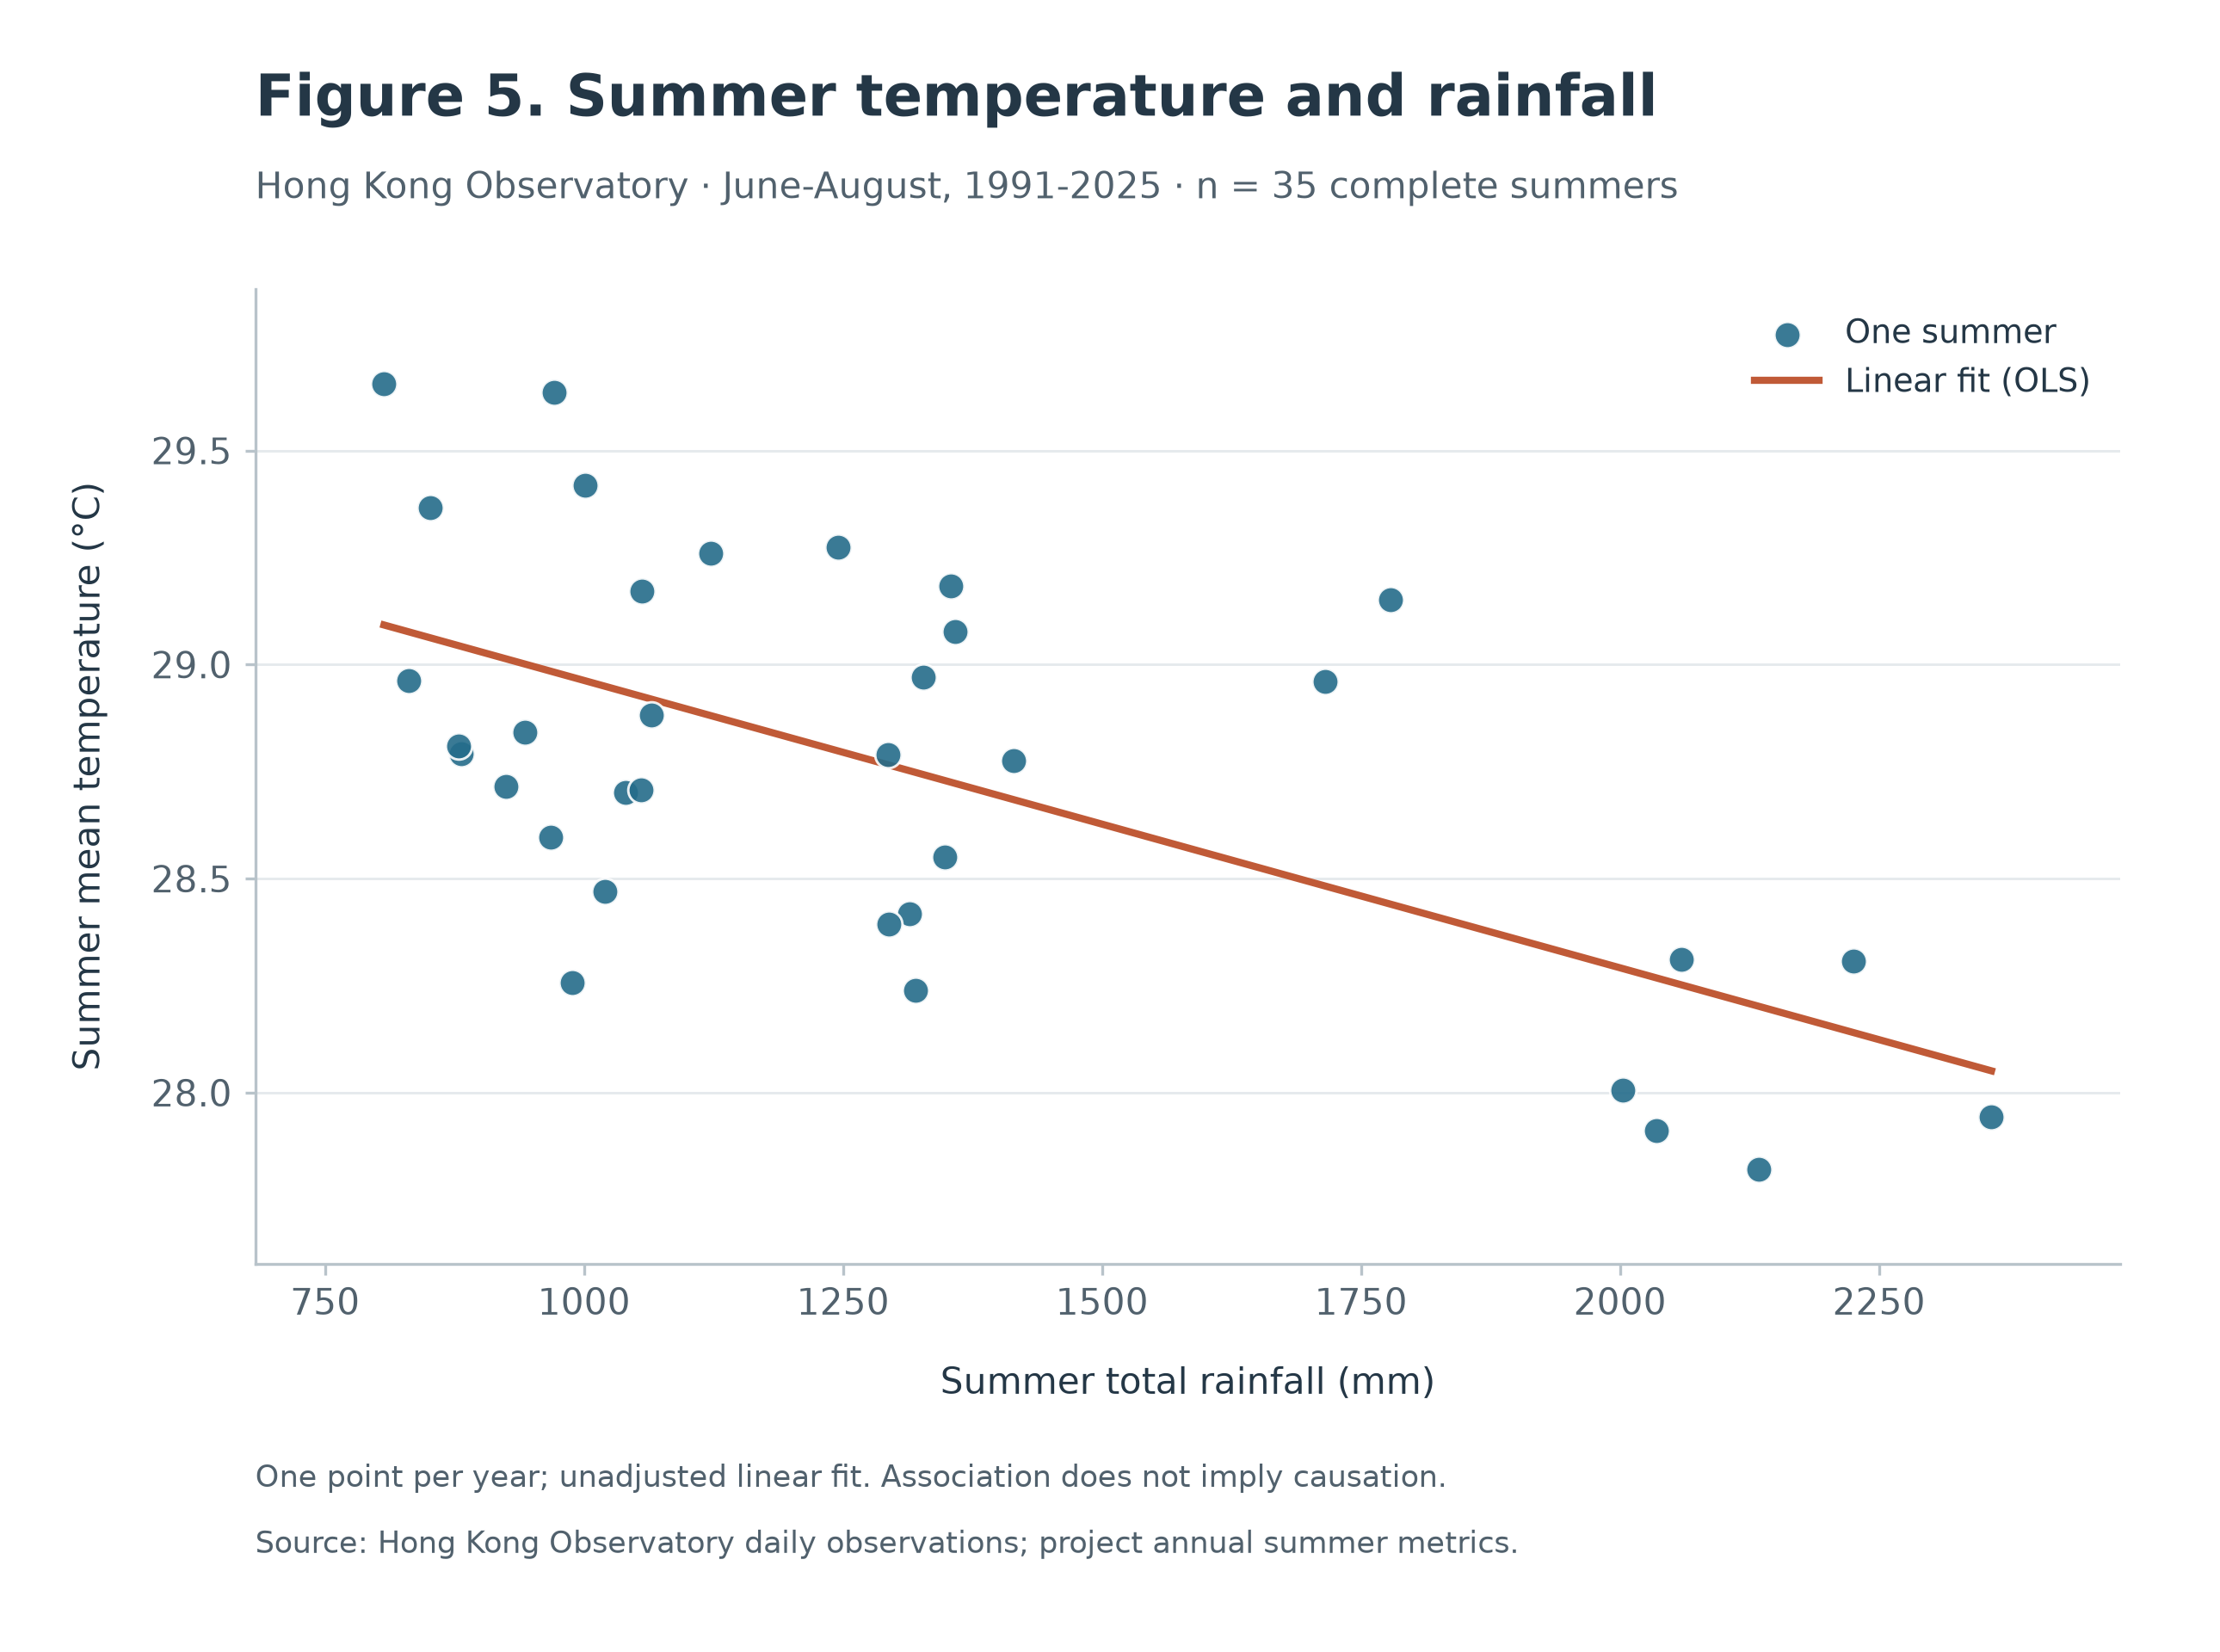

In [3]:
output_dir = project_root / "figures"
output_dir.mkdir(parents=True, exist_ok=True)
png_path = output_dir / "05_temperature_rainfall_scatter.png"
svg_path = output_dir / "05_temperature_rainfall_scatter.svg"
with mpl.rc_context(style):
    figure.savefig(png_path, dpi=300, facecolor="white")
    figure.savefig(svg_path, facecolor="white")
Image(filename=str(png_path), width=860)